# 中金 · 股债双杀预警复现

复现《量化配置系列（3）：巧识尾部相关性，规避组合系统性风险》（中金量化，2021-02-05）。

## 原文口径与本复现口径

| 项 | 原文 | 本复现 |
|---|---|---|
| 股票 | 沪深300 | 同 |
| 债券 | 中债综合财富指数 | 同（直接取自中国债券信息网） |
| 样本期 | 2004/04 – 2020/12 | 同 |
| 尾部相关 | Clayton→λ_D，Gumbel→λ_U，60 日窗口每日滚动 | 同 |
| 边缘分布 | **未说明** | 窗口内秩变换（只用窗口数据，无前视） |
| λ=0 的判定 | **未说明**（只说参数→边界时不相关） | 点估计 λ < 1e-4 即为 0 |
| 趋势 | 「标准 DIF（12 日移动平均 − 26 日移动平均）」 | 按字面用简单均线，EMA 作稳健性 |
| 预警后操作 | 次日股债仓位转货币 | 同，货币按年化 2% 计 |
| 回测基准 | 月末调仓风险平价，目标波动 8% | 同；回看期与杠杆上限原文未给，做敏感性 |

**触发**（同时满足）：λ_D>0、λ_U=0、股或债 DIF<0
**解除**（同时满足）：λ_D=0、债券 DIF>0

## 要回答的问题

1. 预警事件能否对上原文披露的 5 次（2004-10-20、2006-06-14、2008-09-12、2013-06-20、2016-12-12）？
2. λ_D>0 的频率是否超过**相同相关强度、但无尾部相关**的基准？（否则测出的是噪声）
3. 情景③（λ_D>0 且 λ_U=0）的股债次日收益是否双负？（原文核心证据：−0.123% / −0.026%）
4. 叠加预警能否改善风险平价组合？

**纪律**：不为了对上原文而调参数。凡是原文没写、需要我们做选择的地方，都列在上表并做稳健性检验。

## 0 · 环境

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%run ../../01_methods.ipynb

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({
    "figure.figsize": (13, 4),
    "axes.unicode_minus": False,
    "font.sans-serif": ["PingFang SC", "Heiti TC", "Arial Unicode MS", "SimHei", "DejaVu Sans"],
})

## 1 · 数据

中债综合财富指数直接请求中国债券信息网。**注意**：AkShare 的 `bond_composite_index_cbond`
把毫秒时间戳按 UTC 转日期，整条序列错后一天，与股票收益的同日相关被打乱
（与中债新综合指数的日收益相关性只有 0.34，修正后 0.95）。`tailrisk.data` 已绕开这个问题。

In [2]:
EQUITY, BOND = "沪深300", "中债综合财富"
SAMPLE = slice("2004-04-01", "2020-12-31")      # 原文统计区间

prices = load_prices([EQUITY, BOND]).loc["2003-12-01":"2021-02-05"]
returns = to_returns(prices)
print(f"共同交易日 {len(prices)} 天：{prices.index.min():%Y-%m-%d} ~ {prices.index.max():%Y-%m-%d}")
data_quality(prices)

共同交易日 4180 天：2003-12-01 ~ 2021-02-05


,标的,样本数,起点,终点,年化收益,年化波动,最大回撤,零收益占比,唯一值占比,可用
0,沪深300,4180,2003-12-01,2021-02-05,0.094146,0.262157,-0.723038,0.000000,1.0,True
1,中债综合财富,4180,2003-12-01,2021-02-05,0.041016,0.017057,-0.035539,0.000239,1.0,True


## 2 · 滚动尾部相关系数

60 日窗口、每日重估，每个窗口内先做秩变换再拟合 Clayton 与 Gumbel。

In [3]:
roll = rolling_tail_dependence(returns[EQUITY], returns[BOND], window=60, zero_rule="point")
print(f"{len(roll)} 个重估点")
roll[["lambda_D", "lambda_U", "clayton_theta", "gumbel_theta", "ns_corr"]].describe().T

4120 个重估点


,count,mean,std,min,25%,50%,75%,max
lambda_D,4120.0,0.025445,0.066337,0.000000,0.000000,0.000000,0.004689,0.402648
lambda_U,4120.0,0.059323,0.083270,0.000000,0.000000,0.000000,0.106167,0.337721
clayton_theta,4120.0,0.086798,0.142384,0.000007,0.000007,0.000007,0.129256,0.761958
gumbel_theta,4120.0,1.052125,0.078022,1.000006,1.000006,1.000006,1.085412,1.363953
ns_corr,4120.0,-0.022231,0.181008,-0.605353,-0.138301,-0.006907,0.097967,0.431521


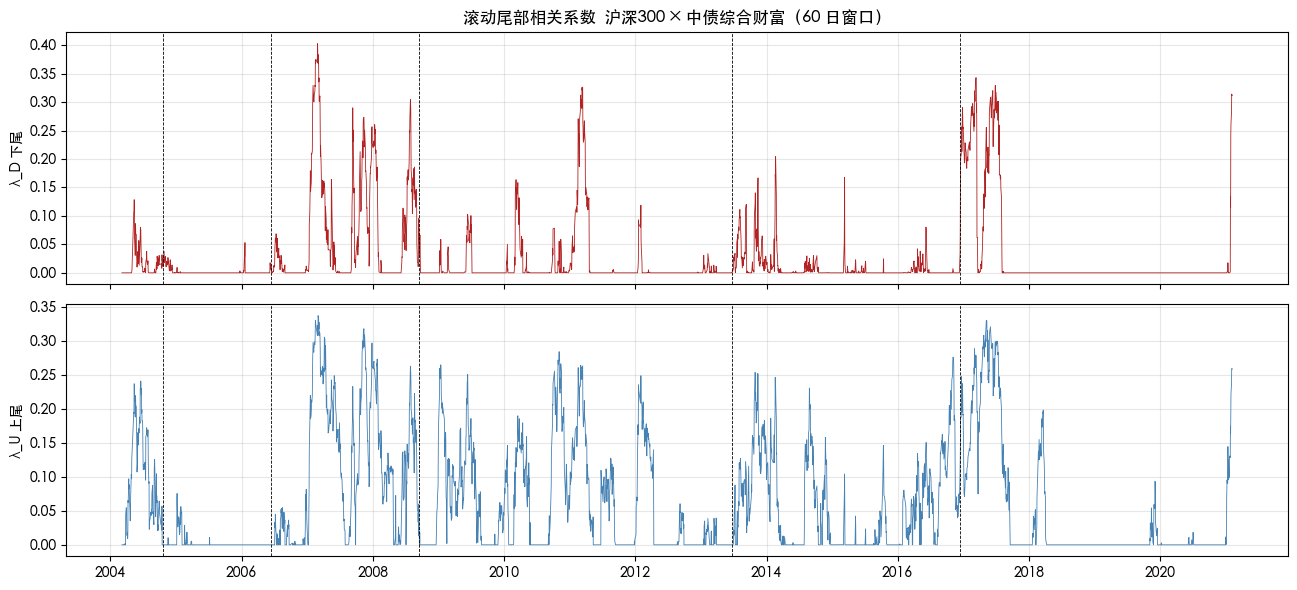

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].plot(roll.index, roll.lambda_D, lw=.6, color="firebrick")
axes[0].set_ylabel("λ_D 下尾")
axes[0].set_title(f"滚动尾部相关系数  {EQUITY} × {BOND}（60 日窗口）")
axes[1].plot(roll.index, roll.lambda_U, lw=.6, color="steelblue")
axes[1].set_ylabel("λ_U 上尾")
for s in CICC_EPISODES["触发"]:
    for ax in axes:
        ax.axvline(s, color="k", lw=.6, ls="--")
for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 2.1 与原文末尾的「当前读数」核对

原文：2021-01-25 起下尾相关系数由 0 开始快速上升，2021-02-04 达到 **27.52%**；
上尾相关系数不为 0，但低于下尾。

In [5]:
roll.loc["2021-01-20":"2021-02-05", ["lambda_D", "lambda_U", "ns_corr"]].style.format("{:.2%}")

,lambda_D,lambda_U,ns_corr
date,,,
2021-01-20 00:00:00,0.00%,10.26%,7.19%
2021-01-21 00:00:00,0.01%,12.86%,9.72%
2021-01-22 00:00:00,0.01%,13.10%,9.84%
2021-01-25 00:00:00,0.16%,12.85%,9.92%
2021-01-26 00:00:00,13.42%,17.49%,17.80%
2021-01-27 00:00:00,11.50%,16.39%,16.77%
2021-01-28 00:00:00,24.41%,19.76%,22.58%
2021-01-29 00:00:00,26.18%,22.23%,24.48%
2021-02-01 00:00:00,28.25%,23.73%,25.87%


## 3 · 预警状态机与逐条核对

In [6]:
def build_signal(roll, prices, dif_kind="ma"):
    dif_e = dif_trend(prices[EQUITY], kind=dif_kind).reindex(roll.index)
    dif_b = dif_trend(prices[BOND], kind=dif_kind).reindex(roll.index)
    return warning_state(roll.lambda_D, roll.lambda_U, dif_e, dif_b)

sig = build_signal(roll, prices)
ep = episodes(sig["预警中"].loc[SAMPLE])
matched, extra = match_episodes(ep, tolerance_days=20)
print(f"复现共 {len(ep)} 次预警（原文 5 次），对上 {matched['复现触发'].notna().sum()} 次")
matched

复现共 15 次预警（原文 5 次），对上 3 次


,触发,解除,原文判定,复现触发,复现解除,触发偏差(天),复现持续交易日
0,2004-10-20,2004-12-06,有效,2004-10-21,2004-12-10,1.0,37.0
1,2006-06-14,2006-08-16,有效,2006-06-13,2006-08-29,-1.0,56.0
2,2008-09-12,2008-09-24,错误信号,NaT,NaT,NaN,NaN
3,2013-06-20,2014-01-15,有效（钱荒）,2013-06-20,2014-01-16,0.0,143.0
4,2016-12-12,2017-03-27,有效（钱荒）,NaT,NaT,NaN,NaN


In [7]:
print("原文没有、复现多出来的预警：")
extra

原文没有、复现多出来的预警：


,触发,解除,持续交易日
1,2004-12-22,2004-12-23,2
2,2004-12-30,2005-01-07,6
4,2007-09-27,2008-02-05,87
5,2008-07-03,2008-09-19,56
6,2013-03-01,2013-03-01,1
7,2013-03-11,2013-03-27,13
9,2014-05-23,2014-05-30,6
10,2014-06-06,2014-06-16,7
11,2014-07-24,2014-10-16,55
12,2015-03-26,2015-04-29,24


### 3.1 原文 5 个触发日前后的 λ 读数

对不上的两次（2008-09-12、2016-12-12）需要看清楚差在哪一项条件。

In [8]:
dif_e = dif_trend(prices[EQUITY]).reindex(roll.index)
dif_b = dif_trend(prices[BOND]).reindex(roll.index)
rows = []
for d in CICC_EPISODES["触发"]:
    i = roll.index.get_indexer([d], method="bfill")[0]
    for k in (-1, 0):
        t = roll.index[i + k]
        rows.append({"原文触发日": d.date(), "日期": t.date(),
                     "λ_D": roll.lambda_D.iloc[i + k], "λ_U": roll.lambda_U.iloc[i + k],
                     "股DIF<0": dif_e.iloc[i + k] < 0, "债DIF<0": dif_b.iloc[i + k] < 0,
                     "复现是否已在预警中": sig["预警中"].iloc[i + k]})
pd.DataFrame(rows).style.format({"λ_D": "{:.2%}", "λ_U": "{:.2%}"})

,原文触发日,日期,λ_D,λ_U,股DIF<0,债DIF<0,复现是否已在预警中
0,2004-10-20,2004-10-19,1.80%,0.00%,False,False,False
1,2004-10-20,2004-10-20,1.12%,0.00%,False,False,False
2,2006-06-14,2006-06-13,1.06%,0.00%,False,True,True
3,2006-06-14,2006-06-14,0.53%,0.00%,False,True,True
4,2008-09-12,2008-09-11,1.46%,1.33%,True,False,True
5,2008-09-12,2008-09-12,9.61%,6.01%,True,False,True
6,2013-06-20,2013-06-19,0.00%,0.00%,True,False,False
7,2013-06-20,2013-06-20,0.06%,0.00%,True,True,True
8,2016-12-12,2016-12-09,0.00%,6.17%,False,True,False
9,2016-12-12,2016-12-12,2.89%,9.50%,False,True,False


**判读**：λ_D 这一侧与原文高度吻合：

- 2008-09-12、2013-06-20、2016-12-12 三次，λ_D 恰好在原文触发日当天由 0（或低位）跳升；
- 2004、2006 两次，原文触发日当天复现的 λ_D>0 且 λ_U=0，触发日 ±1 天的偏差来自 DIF 条件。

对不上的两次差在 **λ_U**：

- 2016-12-12：λ_D 当天由 0 跳到约 3%，但复现的 λ_U 约 9.5%，不为 0，触发条件不满足；
- 2008-09-12：当天复现的 λ_U 约 6%，也不为 0；而且复现在 2008-07 已因更早的信号进入预警。

即原文的 λ_U 判零比本复现更宽松（更多时候为 0）。原文没有披露判零方法，
我们**不去反推参数**来凑这两次 —— 那正是「调参数直到对上」。

## 4 · 噪声基准 ← 最关键的一步

Clayton/Gumbel 只要窗口内有正相关就会给出 λ>0，与有没有尾部相关无关。
所以对照基准必须是 **「与实测窗口相关强度相同、但尾部相关严格为 0」的高斯 copula**，
而不只是独立数据。下面用模拟构造这个基准：对每个实测窗口，按其正态得分相关系数
查高斯世界里同一判别量出现的概率。

In [9]:
null = gaussian_null(window=60, n_sims=6000, seed=1)
r = roll.loc[SAMPLE]
expected = expected_under_gaussian(r, null)
observed = pd.DataFrame({"lambda_D>0": r.lambda_D > 0,
                         "lambda_U>0": r.lambda_U > 0,
                         "中金条件": (r.lambda_D > 0) & (r.lambda_U == 0)})
indep = noise_baseline(window=60, n_rep=2000, rho=0.0, seed=2)

compare = pd.DataFrame({
    "实测": observed.mean(),
    "匹配相关强度的高斯基准": expected.mean(),
    "独立数据基准": [indep["lambda_D>0占比"], indep["lambda_U>0占比"], indep["中金条件命中率"]],
})
compare["实测/匹配基准"] = compare["实测"] / compare["匹配相关强度的高斯基准"]
compare.style.format({c: "{:.2%}" for c in compare.columns[:3]} | {"实测/匹配基准": "{:.2f}"})

,实测,匹配相关强度的高斯基准,独立数据基准,实测/匹配基准
lambda_D>0,33.44%,34.51%,32.90%,0.97
lambda_U>0,49.07%,46.58%,48.90%,1.05
中金条件,4.76%,4.71%,6.65%,1.01


**判读**：倍数接近 1 说明 λ_D>0、以及中金条件的出现频率，**完全可以由
「股债整体相关强度的时变」解释**，不需要任何尾部相关。

另外注意独立数据基准：按原文的点估计判零口径，纯独立数据也有约三分之一的窗口 λ_D>0，
中金条件命中率约 7%。原文「λ_D>0 是股债表现出下尾相关性的必要条件」的说法，
在 60 日窗口下统计上站不住。

## 5 · 情景对照表 ← 原文的核心证据

统计各情景下股债**下一日**收益均值。原文数字一并列出。
t 值为简单 t 统计量（情景日在时间上成簇，真实标准误更大，t 值偏乐观）。

In [10]:
W = 60
fwd = returns.shift(-1).reindex(r.index)
roll_spear = pd.Series(index=r.index, dtype=float)
roll_kend = pd.Series(index=r.index, dtype=float)
ret_idx = returns.index
for t in r.index:
    i = ret_idx.get_loc(t)
    seg = returns.iloc[i - W + 1:i + 1]
    roll_spear[t] = seg[EQUITY].corr(seg[BOND], method="spearman")
    roll_kend[t] = seg[EQUITY].corr(seg[BOND], method="kendall")
pear = returns[EQUITY].rolling(W).corr(returns[BOND]).reindex(r.index)

scenarios = {
    "①历史所有时间":    (pd.Series(True, index=r.index), 0.048, 0.016),
    "②λ_D≠0":          (r.lambda_D > 0,                 0.066, 0.004),
    "③λ_D≠0 且 λ_U=0":  (observed["中金条件"],           -0.123, -0.026),
    "④Pearson>0":      (pear > 0,                       0.062, 0.010),
    "⑤Spearman>0":     (roll_spear > 0,                 0.047, 0.010),
    "⑥Kendall>0":      (roll_kend > 0,                  0.066, 0.010),
}

def tstat(x):
    x = x.dropna()
    return x.mean() / x.std() * np.sqrt(len(x))

rows = []
for name, (mask, e0, b0) in scenarios.items():
    m = mask.fillna(False).astype(bool)
    fe, fb = fwd.loc[m, EQUITY], fwd.loc[m, BOND]
    rows.append({"情景": name, "样本天数": int(m.sum()),
                 "股票(复现)": fe.mean(), "t_股": tstat(fe), "股票(原文)": e0 / 100,
                 "债券(复现)": fb.mean(), "t_债": tstat(fb), "债券(原文)": b0 / 100})
scen = pd.DataFrame(rows).set_index("情景")
scen.style.format({c: "{:.3%}" for c in ["股票(复现)", "股票(原文)", "债券(复现)", "债券(原文)"]}
                  | {"t_股": "{:.2f}", "t_债": "{:.2f}"})

,样本天数,股票(复现),t_股,股票(原文),债券(复现),t_债,债券(原文)
情景,,,,,,,
①历史所有时间,4076,0.047%,1.77,0.048%,0.017%,10.17,0.016%
②λ_D≠0,1363,0.062%,1.28,0.066%,0.011%,3.58,0.004%
③λ_D≠0 且 λ_U=0,194,0.036%,0.24,-0.123%,0.021%,2.34,-0.026%
④Pearson>0,2004,0.040%,1.00,0.062%,0.012%,4.55,0.010%
⑤Spearman>0,1949,0.067%,1.71,0.047%,0.010%,3.86,0.010%
⑥Kendall>0,1958,0.069%,1.77,0.066%,0.011%,4.39,0.010%


**判读**：情景①④⑤⑥与原文量级一致（数据本身对得上），
但情景③**没有**出现股债双负 —— 这正是原文的核心证据，复现不成立。

## 6 · 回测：风险平价 + 预警

原文：月末调仓风险平价（目标波动 8%），预警触发次日股债转货币，解除次日恢复。
原文未给协方差回看期与杠杆上限；股债风险平价债券权重很高，目标波动 8% 需要加杠杆。
下面用 60 日回看，杠杆上限取 2 / 4 / 不设限 三档。

In [11]:
warn_daily = None
rows, yearly = {}, None
for lev in [2, 4, None]:
    w = risk_parity_weights(returns, lookback=60, target_vol=0.08, max_leverage=lev)
    base = portfolio_returns(w, returns, cash_rate=0.02).loc[SAMPLE]
    warn_daily = to_daily(sig["预警中"], base.index)
    strat = overlay_warning(base, warn_daily, cash_rate=0.02)
    tag = f"杠杆≤{lev}" if lev else "不设限"
    rows[(tag, "基准")] = perf_stats(base) | {"平均杠杆": w.sum(axis=1).loc[SAMPLE].mean()}
    rows[(tag, "加预警")] = perf_stats(strat) | {"平均杠杆": w.sum(axis=1).loc[SAMPLE].mean()}
    if lev == 4:
        nav = (1 + pd.DataFrame({"基准": base, "加预警": strat})).cumprod()
        yearly = yearly_table(pd.DataFrame({"基准": base, "加预警": strat}))

print(f"预警天数占比 {warn_daily.mean():.1%}")
pd.DataFrame(rows).T.style.format("{:.2%}", subset=["年化收益", "年化波动", "最大回撤"]).format(
    "{:.2f}", subset=["收益波动比", "超额夏普", "卡玛比率", "平均杠杆"])

预警天数占比 13.4%


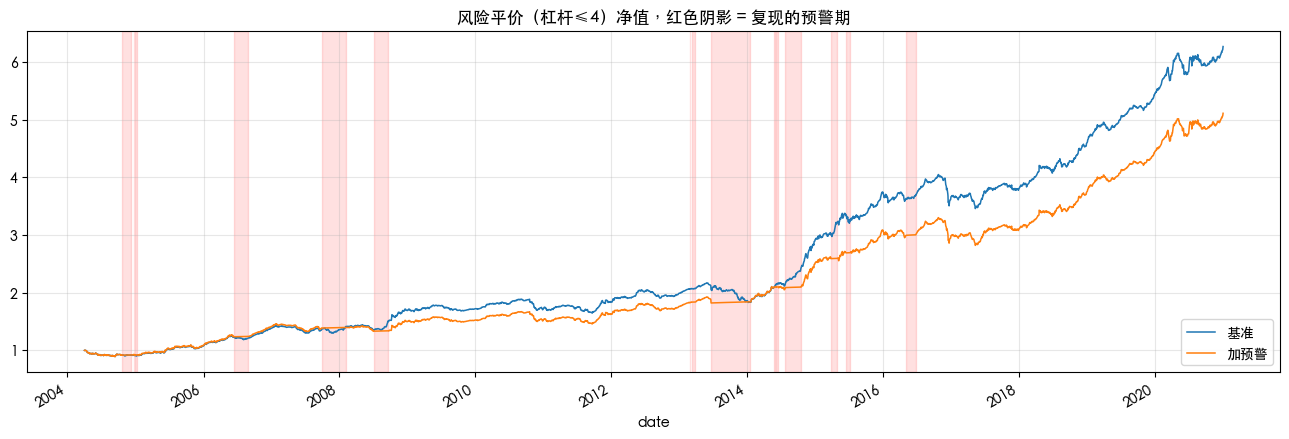

In [12]:
fig, ax = plt.subplots(figsize=(13, 4.5))
nav.plot(ax=ax, lw=1.1)
for _, e in episodes(warn_daily).iterrows():
    ax.axvspan(e["触发"], e["解除"], color="red", alpha=.12)
ax.set_title("风险平价（杠杆≤4）净值，红色阴影 = 复现的预警期"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 6.1 原文预警影响年份的逐年对照（杠杆≤4）

In [13]:
cicc_years = pd.DataFrame({
    ("原文", "加预警年收益"): [-5.67, 30.60, -6.60, 0.79, 27.67, 0.29, 10.03],
    ("原文", "基准年收益"):   [-6.05, 29.60, -4.46, -2.95, 25.92, 0.01, 10.48],
}, index=[2004, 2006, 2008, 2013, 2014, 2016, 2017]) / 100
tbl = pd.concat([yearly.loc[cicc_years.index, [("加预警", "年收益"), ("基准", "年收益")]]
                 .set_axis(pd.MultiIndex.from_tuples([("复现", "加预警年收益"), ("复现", "基准年收益")]), axis=1),
                 cicc_years], axis=1)
tbl.style.format("{:.2%}")

基准的绝对水平与原文有差距（风险平价的回看期、杠杆、协方差估计原文均未披露），
重点看**加预警 − 基准**的方向。2013 年「钱荒」复现与原文一致（预警明显改善），
但全样本上预警拖累了收益：2008、2014 年的错误预警代价很大。

## 7 · 稳健性

每次只改一个口径，看三个核心结论是否改变。

In [14]:
%run ../../01_methods.ipynb

def summarize(name, roll_x, dif_kind="ma", px=prices, rets=returns, rule="point"):
    s = build_signal(roll_x, px, dif_kind)
    e = episodes(s["预警中"].loc[SAMPLE])
    m, _ = match_episodes(e)
    rx = roll_x.loc[SAMPLE]
    cond = (rx.lambda_D > 0) & (rx.lambda_U == 0)
    exp_ = expected_under_gaussian(rx, null, zero_rule=rule)
    f = rets.shift(-1).reindex(rx.index)
    return {"口径": name, "预警次数": len(e), "对上原文": int(m["复现触发"].notna().sum()),
            "中金条件占比": cond.mean(), "匹配基准": exp_["中金条件"].mean(),
            "③股票次日": f.loc[cond, EQUITY].mean(), "③债券次日": f.loc[cond, BOND].mean(),
            "③样本天数": int(cond.sum())}

results = [summarize("主口径", roll)]
results.append(summarize("判零加 LR 检验 (α=5%)", apply_zero_rule(roll, "lrtest"), rule="lrtest"))

results.append(summarize("DIF 用 EMA", roll, dif_kind="ema"))

pit_full = pd.concat([pit_empirical(returns[EQUITY]), pit_empirical(returns[BOND])], axis=1)
roll_full = rolling_tail_dependence(pit_full.iloc[:, 0], pit_full.iloc[:, 1], pit="given")
results.append(summarize("全样本 PIT（有前视）", roll_full))
pd.DataFrame(results).set_index("口径")

,预警次数,对上原文,中金条件占比,匹配基准,③股票次日,③债券次日,③样本天数
口径,,,,,,,
主口径,15,3,0.047596,0.047079,0.000364,0.000214,194
判零加 LR 检验 (α=5%),6,1,0.025025,0.026691,0.001798,0.000093,102
DIF 用 EMA,15,3,0.047596,0.047079,0.000364,0.000214,194
全样本 PIT（有前视）,18,2,0.081207,0.047583,0.002641,0.000107,331


In [15]:
# 换债券标的：上证国债指数（原先 notebook 的退路方案）
px_alt = load_prices([EQUITY, "上证国债指数"]).loc["2003-12-01":"2021-02-05"]
px_alt.columns = [EQUITY, BOND]
ret_alt = to_returns(px_alt)
roll_alt = rolling_tail_dependence(ret_alt[EQUITY], ret_alt[BOND])
pd.DataFrame([summarize("债券换成上证国债指数", roll_alt, px=px_alt, rets=ret_alt)]).set_index("口径")

,预警次数,对上原文,中金条件占比,匹配基准,③股票次日,③债券次日,③样本天数
口径,,,,,,,
债券换成上证国债指数,17,1,0.038273,0.046503,-0.00041,0.000154,156


## 8 · 结论

| 问题 | 结论 |
|---|---|
| 1. 预警事件对得上吗 | **部分**。λ_D 侧吻合：5 个原文触发日中 3 次 λ_D 当天跳升、2 次当天已满足条件。预警事件对上 3 次（2004、2006、2013，偏差 ≤1 天，2013 年持续 143 天 vs 原文 142 天）。2008、2016 两次差在 λ_U 判零。复现另多出 12 次预警 |
| 2. 信号是否超过噪声 | **否**。λ_D>0 与中金条件的出现频率，和「相同相关强度、无尾部相关」的高斯基准几乎相等 |
| 3. 情景③股债双负吗 | **否**。股票次日收益约为 0，债券显著为正 |
| 4. 回测改善吗 | 2013 年钱荒有效，全样本不改善（三档杠杆下收益波动比均下降） |

稳健性（第 7 节）：判零加 LR 检验、DIF 改 EMA、债券换上证国债指数，情景③都不是双负。
全样本 PIT 让中金条件占比从 4.8% 升到 8.1%，明显高于匹配基准 —— 但这来自波动率聚集
（全样本秩变换下，危机窗口里两边的 u 同时挤向两端），且该口径有前视偏差。

**总体判定：原文的计算流程基本可以重现（λ_D 的时点吻合），但其核心证据（情景③双负）在同一数据上不成立，
且信号的出现频率与无尾部相关的基准不可区分。** 原文 5 次预警「准确率 80%」只有 5 个样本，
无法与运气区分。

已知差异与未决问题：

- 原文 λ_U 的判零方法未披露，复现的 λ_U 比原文更少为 0。
- 风险平价基准的细节未披露，绝对收益对不上，只比较方向。
- 原文中的多资产（股/债/金）与全球资产下尾相关均值两部分，见本目录后续 notebook。